In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/synthetic_opd_cohort_500.csv")
df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (500, 17)


,patient_id,age,gender,symptoms,medical_history,respiratory_rate,spo2,on_oxygen,systolic_bp,diastolic_bp,pulse,temperature_c,consciousness,disease_category,icd10_code,severity,admission_outcome
0,P0001,54,Female,weakness;increased thirst;fatigue;frequent uri...,type 2 diabetes,17.0,99.0,0,110.0,67.0,NaN,36.6,Alert,Endocrine_Metabolic,E11.9,Mild,Discharged
1,P0002,21,Female,burning chest;sour burp,obesity;gerd,16.0,99.0,0,125.0,72.0,79.0,NaN,Alert,Digestive,K21.9,Mild,Discharged
2,P0003,52,Female,joint pain;breathlessness on exertion;weight g...,hypertension,17.0,98.0,0,137.0,81.0,53.0,36.3,Alert,Endocrine_Metabolic,E66.9,Mild,Discharged
3,P0004,44,Female,cold;cough;running nose;mild fever,none,NaN,96.0,0,110.0,59.0,69.0,36.6,Alert,Respiratory,J00,Mild,Discharged
4,P0005,57,Female,blurred vision;dizziness;fatigue;palpitations,smoking;diabetes,16.0,99.0,0,127.0,70.0,82.0,36.7,Alert,Circulatory,I10,Mild,Discharged


In [2]:
# 1. Column types and non-empty counts
df.info()

# 2. Which columns have missing values, and how many
print("\nMissing values per column:")
missing = df.isna().sum()
print(missing[missing > 0])

# 3. Summary statistics for the number columns
df.describe().round(1)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         500 non-null    str    
 1   age                500 non-null    int64  
 2   gender             500 non-null    str    
 3   symptoms           500 non-null    str    
 4   medical_history    500 non-null    str    
 5   respiratory_rate   479 non-null    float64
 6   spo2               487 non-null    float64
 7   on_oxygen          500 non-null    int64  
 8   systolic_bp        487 non-null    float64
 9   diastolic_bp       482 non-null    float64
 10  pulse              488 non-null    float64
 11  temperature_c      476 non-null    float64
 12  consciousness      500 non-null    str    
 13  disease_category   500 non-null    str    
 14  icd10_code         500 non-null    str    
 15  severity           500 non-null    str    
 16  admission_outcome  500 non-null    st

,age,respiratory_rate,spo2,on_oxygen,systolic_bp,diastolic_bp,pulse,temperature_c
count,500.0,479.0,487.0,500.0,487.0,482.0,488.0,476.0
mean,46.1,18.1,96.7,0.0,126.0,77.7,82.8,37.4
std,19.0,3.2,2.0,0.2,15.5,9.8,16.0,5.0
min,1.0,10.0,88.0,0.0,20.0,48.0,52.0,36.0
25%,34.0,16.0,95.0,0.0,117.5,71.0,74.8,36.7
50%,48.0,18.0,97.0,0.0,125.0,78.0,82.0,36.9
75%,59.0,20.0,98.0,0.0,134.0,84.0,89.0,37.2
max,150.0,29.0,100.0,1.0,260.0,113.0,300.0,100.3


          column     Q1    Q3   IQR  lower_fence  upper_fence  n_outliers
             age  34.00  59.0 25.00         -3.5         96.5           1
respiratory_rate  16.00  20.0  4.00         10.0         26.0           5
            spo2  95.00  98.0  3.00         90.5        102.5           4
     systolic_bp 117.50 134.0 16.50         92.8        158.8          11
    diastolic_bp  71.00  84.0 13.00         51.5        103.5           5
           pulse  74.75  89.0 14.25         53.4        110.4           5
   temperature_c  36.70  37.2  0.50         36.0         38.0          21


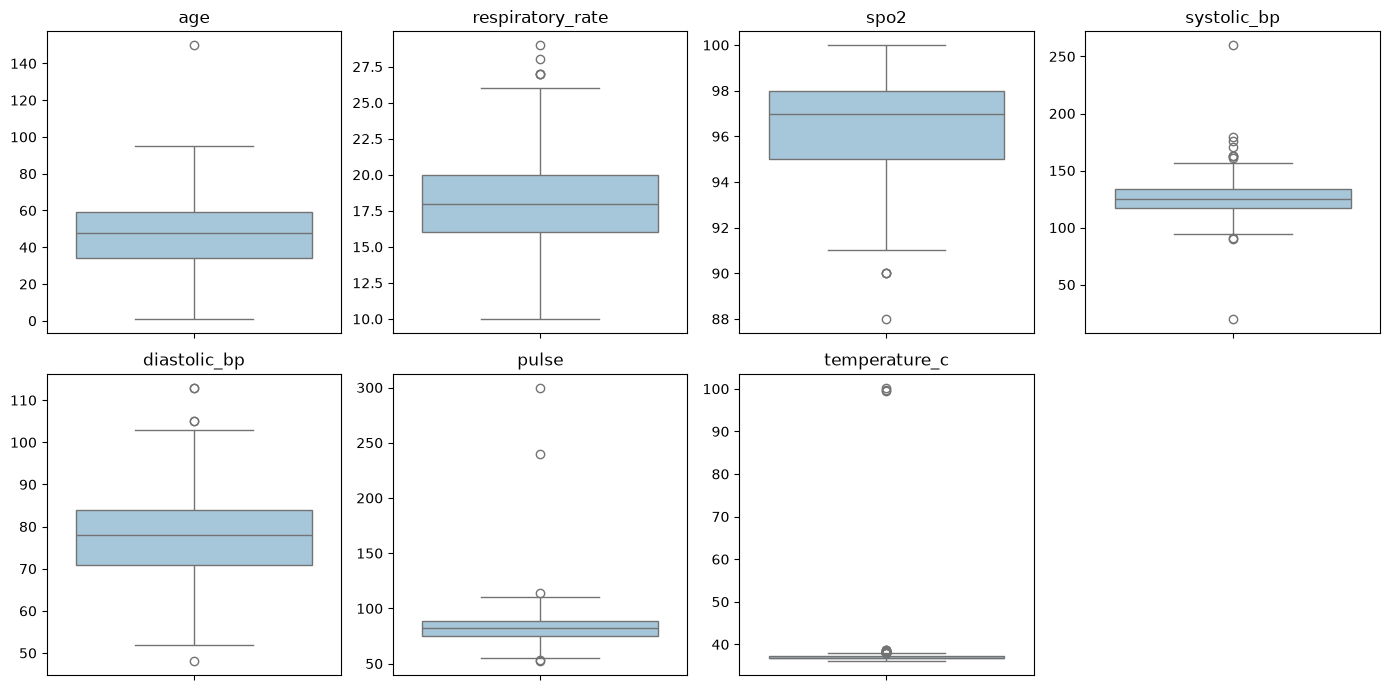

In [3]:
numeric_cols = ["age", "respiratory_rate", "spo2", "systolic_bp",
                "diastolic_bp", "pulse", "temperature_c"]

rows = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({
        "column": col,
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": round(low, 1),
        "upper_fence": round(high, 1),
        "n_outliers": int(n_out),
    })

outlier_table = pd.DataFrame(rows)
print(outlier_table.to_string(index=False))

# Boxplots: dots beyond the whiskers are the IQR outliers
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#9ecae1")
    ax.set_title(col)
    ax.set_ylabel("")
axes.flat[-1].axis("off")      # the 8th panel is empty
plt.tight_layout()
plt.show()

In [4]:
clean = df.copy()
clean[numeric_cols] = clean[numeric_cols].astype(float)   # allows empty (NaN) cells

print("Missing before cleaning:")
print(clean[numeric_cols].isna().sum().to_string())

# Step A: temperatures that are clearly Fahrenheit -> Celsius
f_mask = clean["temperature_c"] > 45
print("\nFahrenheit temperatures converted:", int(f_mask.sum()))
clean.loc[f_mask, "temperature_c"] = ((clean.loc[f_mask, "temperature_c"] - 32) / 1.8).round(1)

# Step B: physiologically impossible values -> empty
limits = {
    "age": (1, 100),
    "respiratory_rate": (4, 60),
    "spo2": (70, 100),
    "systolic_bp": (50, 250),
    "diastolic_bp": (30, 140),
    "pulse": (30, 200),
    "temperature_c": (34, 42),
}
print("\nImpossible values set to empty:")
for col, (lo, hi) in limits.items():
    bad = (clean[col] < lo) | (clean[col] > hi)
    if bad.any():
        print(f"  {col}: {int(bad.sum())} value(s) -> {clean.loc[bad, col].tolist()}")
    clean.loc[bad, col] = np.nan

# Step C: fill empty cells with the median of the same severity group
for col in numeric_cols:
    clean[col] = clean[col].fillna(clean.groupby("severity")[col].transform("median"))

# Whole numbers for everything except temperature
for col in numeric_cols:
    if col != "temperature_c":
        clean[col] = clean[col].round().astype(int)

print("\nMissing after cleaning:", int(clean.isna().sum().sum()))
clean[numeric_cols].describe().round(1)

Missing before cleaning:
age                  0
respiratory_rate    21
spo2                13
systolic_bp         13
diastolic_bp        18
pulse               12
temperature_c       24

Fahrenheit temperatures converted: 3

Impossible values set to empty:
  age: 1 value(s) -> [150.0]
  systolic_bp: 2 value(s) -> [20.0, 260.0]
  pulse: 2 value(s) -> [300.0, 240.0]

Missing after cleaning: 0


,age,respiratory_rate,spo2,systolic_bp,diastolic_bp,pulse,temperature_c
count,500.0,500.0,500.0,500.0,500.0,500.0,500.0
mean,45.9,18.1,96.7,125.9,77.7,81.9,37.0
std,18.5,3.2,2.0,13.2,9.6,10.2,0.4
min,1.0,10.0,88.0,90.0,48.0,52.0,36.0
25%,34.0,16.0,95.0,118.0,71.0,75.0,36.7
50%,48.0,18.0,97.0,125.0,78.0,82.0,36.9
75%,59.0,20.0,98.0,134.0,84.0,88.0,37.2
max,95.0,29.0,100.0,179.0,113.0,114.0,38.7


In [5]:
CLEAN_PATH = Path("../data/synthetic_opd_cohort_500_clean.csv")
clean.to_csv(CLEAN_PATH, index=False)

# Reload the saved file and double-check it
check = pd.read_csv(CLEAN_PATH)
print("Saved:", CLEAN_PATH)
print("Shape:", check.shape)
print("Total missing cells:", int(check.isna().sum().sum()))
print("Columns match the original:", list(check.columns) == list(df.columns))
print()
print(check["admission_outcome"].value_counts().to_string())

Saved: ..\data\synthetic_opd_cohort_500_clean.csv
Shape: (500, 17)
Total missing cells: 0
Columns match the original: True

admission_outcome
Discharged    415
Admitted       85


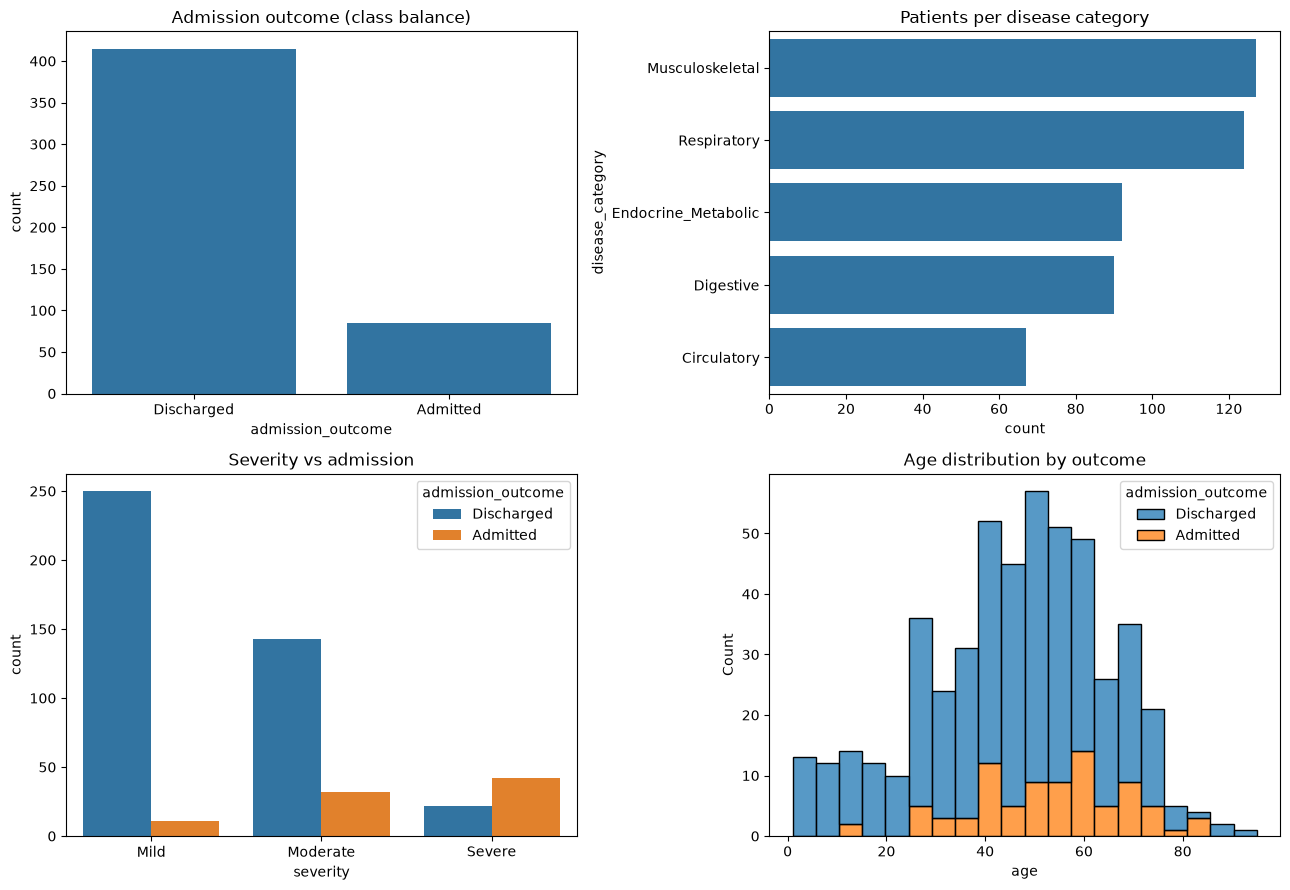

In [6]:
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=clean, x="admission_outcome",
              order=["Discharged", "Admitted"], ax=axes[0, 0])
axes[0, 0].set_title("Admission outcome (class balance)")

sns.countplot(data=clean, y="disease_category",
              order=clean["disease_category"].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title("Patients per disease category")

sns.countplot(data=clean, x="severity", hue="admission_outcome",
              order=["Mild", "Moderate", "Severe"],
              hue_order=["Discharged", "Admitted"], ax=axes[1, 0])
axes[1, 0].set_title("Severity vs admission")

sns.histplot(data=clean, x="age", hue="admission_outcome",
             multiple="stack", bins=20, ax=axes[1, 1])
axes[1, 1].set_title("Age distribution by outcome")

plt.tight_layout()
plt.savefig(FIG_DIR / "distributions.png", dpi=150)
plt.show()

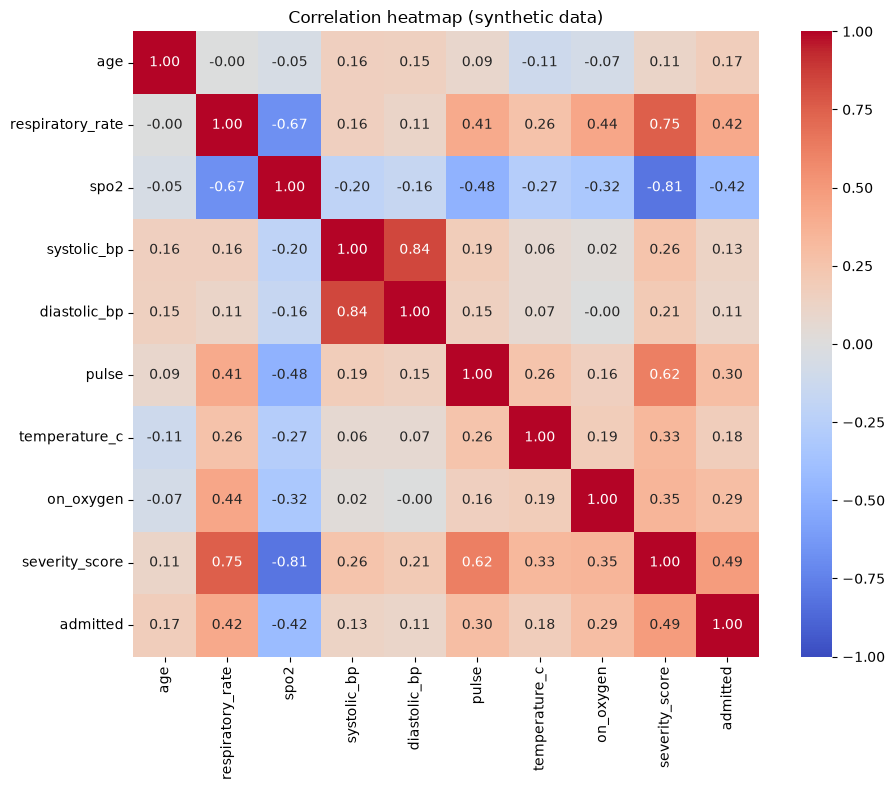

Correlation with admission (strongest first):
severity_score      0.49
respiratory_rate    0.42
pulse               0.30
on_oxygen           0.29
temperature_c       0.18
age                 0.17
systolic_bp         0.13
diastolic_bp        0.11
spo2               -0.42


In [7]:
corr_df = clean[numeric_cols + ["on_oxygen"]].copy()
corr_df["severity_score"] = clean["severity"].map({"Mild": 0, "Moderate": 1, "Severe": 2})
corr_df["admitted"] = (clean["admission_outcome"] == "Admitted").astype(int)

corr = corr_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap (synthetic data)")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with admission (strongest first):")
print(corr["admitted"].drop("admitted").sort_values(ascending=False).round(2).to_string())